# Multiwavelength fold — LDI v/s RK4

One restore event fitted to the multilayer fold train sampled by
`04a_multiwavelength_fold_data`: six horizons H0 (youngest) to H5, whose
wavelength changes along the section and from layer to layer. Restore pulls
a flat layer-cake back through a volume-preserving Euler flow; there is no
direct scalar interpolant here.

**Integrators.** The notebook fits the same restore twice, one integrator after
the other (`INTEGRATORS`): `"shear"` (one Quispel–McLaren shear sequence) and
`"rk4"` (the classical Runge–Kutta flow of the same velocity), with `n_steps` from
`big_fold_inputs.INTEGRATORS`. Everything else is the same: Fourier basis, seed,
data, weights and training, and the random state is reset before each fit. Each
fit is saved to its own `results/<integrator>/`.

**Training.** The energy-biased scheme of the other examples:
energy-normalised cubic modes, amplitudes started at zero and trained by plain
SGD (momentum), phase and bias trained by Adam. A weak orthogonal-thickness
prior is kept from the original fit.

**What this notebook is.** Computation and quick checks only. Saved to
`results/<integrator>/`, for `04c_multiwavelength_fold_figures`:

- `fit.npz` — the evaluation grid, lithology, restored traces, strain ellipses,
  inverse pathlines, the reference grid carried into the present, det DΦ⁻¹,
  and the shear modes of the fitted velocity;
- `summary.json` — the numbers quoted in the text (restored-depth scatter,
  area error, layer shortening); `fit_settings.json`; `restore_field.pt`.

## Setup

In [12]:
import json
import random
from pathlib import Path
from time import perf_counter

import numpy as np
import torch
import matplotlib.pyplot as plt

import curlew
from curlew.core import CSet, HSet
from curlew.geometry import Grid
from curlew.geology import restore
from curlew.kinematics.constraints import OrthogonalThickness
from curlew.kinematics.euler import euler_velocity
from curlew.kinematics.training import SpectralWarmup
from curlew.priors.spectral import spectral_band, n_features_for_band

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics
import figstyle
import diagnostics
import big_fold_inputs as bfi  # observations, results folders and shortening, shared with 04a and 04c
figstyle.apply()

curlew.device = "cuda" if torch.cuda.is_available() else "cpu"
curlew.dtype = torch.float32
curlew.default_dim = 2

SEED = 404
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

INTEGRATORS = ("shear", "rk4")   # fitted one after the other, each saved to results/<integrator>/
for integrator in INTEGRATORS:
    bfi.results_dir(integrator).mkdir(parents=True, exist_ok=True)
print(f"device={curlew.device}; fits: " + ", ".join(f"{k} (n_steps {bfi.INTEGRATORS[k]}) -> {bfi.results_dir(k)}"
                                                   for k in INTEGRATORS))

device=cpu; fits: shear (n_steps 0) -> results/shear, rk4 (n_steps 5) -> results/rk4


## Observations and constraints

- `gp`, `gv` — bedding normals with younging (`grad_loss`);
- `eq` — each horizon's clumps share a restored depth (`eq_loss`);
- `iq` — younger horizons restore above older ones.

In [13]:
obs = bfi.load_observations()
horizon_names, horizons_full, horizons = obs["horizon_names"], obs["horizons_full"], obs["horizons"]
gp, gv = obs["gp"], obs["gv"]

IQ_SAMPLES = 64
iq_pairs = [(horizons[i], horizons[i + 1], ">") for i in range(len(horizons) - 1)]
C = CSet(gp=gp, gv=gv, eq=horizons, iq=(IQ_SAMPLES, iq_pairs))
anchor = torch.zeros(2, dtype=curlew.dtype, device=curlew.device)
print(f"horizons {horizon_names}, clumps {[len(h) for h in horizons]}, bedding {len(gp)}")

horizons ['H0', 'H1', 'H2', 'H3', 'H4', 'H5'], clumps [200, 200, 200, 90, 200, 200], bedding 50


## Evaluation grid

The full 1600 × 220 box at 2 (model units).

In [14]:
G = Grid((1600, 220), step=(2.0, 2.0), center=np.zeros(2), sampleArgs=dict(N=64))
domaxes = G.tformed_axes
grd = torch.tensor(G.coords(), dtype=curlew.dtype, device=curlew.device)
xlim = (float(domaxes[0][0]), float(domaxes[0][-1]))
zlim = (float(domaxes[1][0]), float(domaxes[1][-1]))
print("grid", G.shape, "x", xlim, "z", zlim)

grid (800, 110) x (-800.0, 798.0) z (-110.0, 108.0)


## Restore

A cubic random Fourier stream function α, whose wavelength band is read off the data's
spectral moments (`curlew.priors.spectral.spectral_band`: contacts give the variance of horizon
heights, bedding the variance of slopes, neighbouring bedding the variance of curvatures;
`L_min` is the shorter of the hinge and limb spacings, `L_max` the longer, and at least two
octaves above `L_min` and the data's diameter), with a fixed number of modes per octave; in 2-D the second potential is the
section normal. The scalar is restored depth φ(*x*) = (Φ⁻¹*x*)[*z*] and bedding
is matched after Nanson transport. `eq_sample` draws points from each clump at
every step. `OrthogonalThickness` is sampled in the restored frame between the
top and bottom horizons.

In [15]:
MODES_PER_OCTAVE = 128
N_DIRECTIONS = 16
LSR, BAND_INFO = spectral_band(C, return_info=True)
N_FEATURES = n_features_for_band(LSR, MODES_PER_OCTAVE, N_DIRECTIONS)
print(f"band {LSR[0]:.0f}-{LSR[1]:.0f} | M {N_FEATURES} |", BAND_INFO)
EPOCHS = 2000
WEIGHTS = dict(grad_loss="0.01", eq_loss="1.")
FOURIER_SEED = 404

# Energy-biased training
LR_ADAM = 5e-3          # Adam rate for phase and bias
LR_SGD = 1e-1            # SGD rate for the amplitudes
AMP_MOMENTUM = 0.9
INIT_STD = 0.0

# Spectral warm-up (curlew.kinematics.training.SpectralWarmup): the octaves of the band are let in from
# the longest to the shortest over the first 1/6 of the epochs, so the long modes get a head start.
SPECTRAL_WARMUP = False

runs = {}
for integrator in INTEGRATORS:
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)       # same random state (eq_sample draws) for both fits
    velocity = euler_velocity(
        2, n_features=N_FEATURES, n_directions=N_DIRECTIONS, length_scale_range=LSR,
        stream="alpha", activation="cubic", seed=FOURIER_SEED, energy_normalised=True,
    )
    event_restore = restore(
        "big_fold_restore", C=C, H=HSet().zero(**WEIGHTS), velocity=velocity,
        n_steps=bfi.INTEGRATORS[integrator], integrator=integrator, depth_axis=1,
        init_std=INIT_STD, sigma_floor=0., signed_normals=True, learning_rate=LR_ADAM,
        optimizer={
            "amplitude": (torch.optim.SGD, dict(lr=LR_SGD, momentum=AMP_MOMENTUM)),
            "shape": (torch.optim.Adam, dict(lr=LR_ADAM)),
        },
        pin=anchor,
    )
    for name, h in zip(reversed(horizon_names), reversed(horizons)):
        event_restore.addIsosurface(name, seed=h)
    model_restore = curlew.GeoModel([event_restore])

    print(f"--- {integrator} (n_steps {bfi.INTEGRATORS[integrator]})")
    t0 = perf_counter()
    with SpectralWarmup(event_restore) as schedule:
        model_restore.prefit(epochs=EPOCHS, vb=True, early_stop=None,
                             schedule=schedule if SPECTRAL_WARMUP else None)
    fit_seconds = perf_counter() - t0
    print(f"{integrator}: fitted in {fit_seconds:.1f} s")
    runs[integrator] = dict(event=event_restore, model=model_restore, fit_seconds=fit_seconds)

/Users/kamath92/anaconda3/envs/curlew_dev/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3701: UserWarning: CSet has crs='global'; spectral_band assumes positions are already in the coordinate system used for fitting. When a GeoModel transform applies, call CSet.to_model(T) or bind through the model first.
  exec(code_obj, self.user_global_ns, self.user_ns)
/Users/kamath92/Documents/Work/2026/DevOps/curlew/curlew/priors/spectral.py:790: UserWarning: CSet has crs='global'; spectral_band assumes positions are already in the coordinate system used for fitting. When a GeoModel transform applies, call CSet.to_model(T) or bind through the model first.
  mom = spectral_moments(data, axis=axis)


band 65-1597 | M 592 | {'m0': 378.51395879989036, 'm2': 0.5080893688620468, 'm4': 0.004739644812865671, 'lambda_x': 65.05445214376279, 'lambda_0': 171.49472431099332, 'normal': [0.025581949214795237, 0.9996727283838305], 'normal_from_contacts': True, 'resolved': True, 'lambda_x_error': 0.24108544876863736, 'n_curvature': 100.56857855361594, 'window': 15.32425363397151, 'contact_noise': 0.6895106763929618, 'n_eff': 1.0, 'n_bedding': 50, 'n_contacts': 1090, 'n_pairs': 1, 'n_windows': 109, 'n_horizons_spanning': 5, 'profile': False, 'diameter': 1597.0237567604743, 'strain': None}
--- shear (n_steps 0)


L=0.002 grad_loss=0.000 eq_loss=0.002: : 2000/2000|


shear: fitted in 24.8 s
--- rk4 (n_steps 5)


L=0.008 grad_loss=0.001 eq_loss=0.007: : 2000/2000|

rk4: fitted in 771.3 s


## Evaluate

- **lithology** on the grid;
- **restored traces**: the dense polylines (not the clumps) through Φ⁻¹, and the
  scatter of restored depth along each;
- **area**: det DΦ⁻¹ on the grid.

In [16]:
for integrator, R in runs.items():
    field, flow = R["event"].field, R["event"].field.integrator
    with torch.no_grad():
        lithology = np.asarray(G.reshape(R["model"].predict(grd, litho=True).lithoID))
        restored_full = [field.inverse_map(torch.as_tensor(h, dtype=curlew.dtype, device=curlew.device)).cpu().numpy()
                         for h in horizons_full]
        _, jac = flow.inverse_map_with_jacobian(grd)
        det = np.asarray(G.reshape(torch.linalg.det(jac).cpu().numpy()), dtype=float)

    depth_sd = [float(r[:, 1].std()) for r in restored_full]
    depth_mean = [float(r[:, 1].mean()) for r in restored_full]
    in_order = bool(np.all(np.diff(depth_mean) < 0))
    shortening = bfi.layer_shortening(horizons_full, restored_full)
    R.update(lithology=lithology, restored_full=restored_full, det=det, depth_sd=depth_sd,
             depth_mean=depth_mean, in_order=in_order, shortening=shortening)

    print(f"--- {integrator}")
    print("restored depth (model units):", {n: f"{m:.1f} ± {s:.1f}" for n, m, s in zip(horizon_names, depth_mean, depth_sd)},
          "| in stratigraphic order:", in_order)
    print(f"max |det DΦ⁻¹ - 1| = {np.abs(det - 1).max():.2e}")
    print(f"{'horizon':<8} {'W':>8} {'W0':>8} {'arc':>8} {'1-W/W0':>9} {'1-W/arc':>9}")
    for i, n in enumerate(horizon_names):
        print(f"{n:<8} {shortening['W'][i]:8.1f} {shortening['W0'][i]:8.1f} {shortening['arc'][i]:8.1f} "
              f"{shortening['from_restored'][i]:8.1f}% {shortening['from_arc'][i]:8.1f}%")
    print(f"benchmark {shortening['benchmark']:.1f}%")

--- shear
restored depth (model units): {'H0': '63.1 ± 2.4', 'H1': '30.1 ± 2.9', 'H2': '21.3 ± 1.7', 'H3': '1.9 ± 0.3', 'H4': '-15.4 ± 2.7', 'H5': '-57.7 ± 6.1'} | in stratigraphic order: True
max |det DΦ⁻¹ - 1| = 7.15e-07
horizon         W       W0      arc    1-W/W0   1-W/arc
H0         1546.7   1549.8   1826.4      0.2%     15.3%
H1         1570.2   1565.2   2000.3     -0.3%     21.5%
H2          657.7    787.0    938.4     16.4%     29.9%
H3          195.7    179.9    218.4     -8.8%     10.4%
H4         1575.6   1622.4   2034.7      2.9%     22.6%
H5         1543.0   1637.2   2091.3      5.8%     26.2%
benchmark 27.8%
--- rk4
restored depth (model units): {'H0': '65.3 ± 4.0', 'H1': '32.0 ± 3.4', 'H2': '22.9 ± 2.2', 'H3': '2.4 ± 0.5', 'H4': '-14.2 ± 3.8', 'H5': '-57.0 ± 6.1'} | in stratigraphic order: True
max |det DΦ⁻¹ - 1| = 1.18e-03
horizon         W       W0      arc    1-W/W0   1-W/arc
H0         1546.7   1523.4   1826.4     -1.5%     15.3%
H1         1570.2   1532.1   2000.3 

## Strain, pathlines and the reference grid

- **strain ellipses** at Poisson-disk points inside the fold package
  (`diagnostics.strain_sample_points`, `strain_measures`);
- **inverse pathlines** of each velocity factor from 1000 seeds and the pin
  (`diagnostics.factor_pathlines`): one vertex per Runge–Kutta step for RK4,
  one per translation for the shear sequence;
- **the reference grid carried into the present**: iso-depth lines and material
  columns in the restored frame, pushed through Φ;
- **shear modes** of the fitted velocity (`diagnostics.shear_modes`), for the
  spectrum.

In [17]:
xy_strain, strain_radius = diagnostics.strain_sample_points(
    horizons_full, grid=G, spacing=0.04 * abs(zlim[1] - zlim[0]), max_points=8000, seed=SEED + 11,
)
anchor_xy = anchor.cpu().numpy()
path_seeds = diagnostics.pathline_seeds(domaxes[0], domaxes[1], grid=G, n_seeds=1000, extra=anchor_xy)

N_ALONG, LINE_DX = 501, 10.0
pad_x, pad_z = 0.5 * (xlim[1] - xlim[0]), 0.5 * (zlim[1] - zlim[0])
xmin, xmax, zmin, zmax = xlim[0] - pad_x, xlim[1] + pad_x, zlim[0] - pad_z, zlim[1] + pad_z
x_lines = np.arange(xmin, xmax + 0.5 * LINE_DX, LINE_DX)
z_lines = np.arange(zmin, zmax + 0.5 * LINE_DX, LINE_DX)
s_x, s_z = np.linspace(xmin, xmax, N_ALONG), np.linspace(zmin, zmax, N_ALONG)
paleo = np.concatenate([
    np.stack([np.stack([s_x, np.full(N_ALONG, z)], axis=-1) for z in z_lines]).reshape(-1, 2),
    np.stack([np.stack([np.full(N_ALONG, x), s_z], axis=-1) for x in x_lines]).reshape(-1, 2),
])
for integrator, R in runs.items():
    event_restore = R["event"]
    flow = event_restore.field.integrator
    strain = diagnostics.strain_measures(event_restore, xy_strain)
    pathlines = diagnostics.factor_pathlines(event_restore, path_seeds)
    factor_names = diagnostics.factor_labels(event_restore)
    with torch.no_grad():
        y = torch.tensor(paleo, dtype=curlew.dtype, device=curlew.device)
        present = flow.map_to_time(y + flow.frame_offset, 1.0, forward=True).cpu().numpy()
    modes = diagnostics.shear_modes(event_restore)
    R.update(strain=strain, pathlines=pathlines, factor_names=factor_names, present=present, modes=modes)
    print(f"{integrator}: {len(xy_strain)} strain ellipses (median axial ratio {np.median(strain['Rs']):.2f}); "
          f"{len(pathlines)} pathline set(s) of {len(path_seeds)} seeds, "
          + ", ".join(f"{n}: {p.shape[0] - 1} legs" for n, p in zip(factor_names, pathlines))
          + f"; {sum(len(m[1]) for m in modes)} shear modes")

shear: 2142 strain ellipses (median axial ratio 2.16); 1 pathline set(s) of 1000 seeds, Band 1: 16 legs; 1776 shear modes
rk4: 2142 strain ellipses (median axial ratio 2.13); 1 pathline set(s) of 1000 seeds, Band 1: 5 legs; 1776 shear modes


## Quick check

Lithology with the contacts, and the restored traces (not saved).

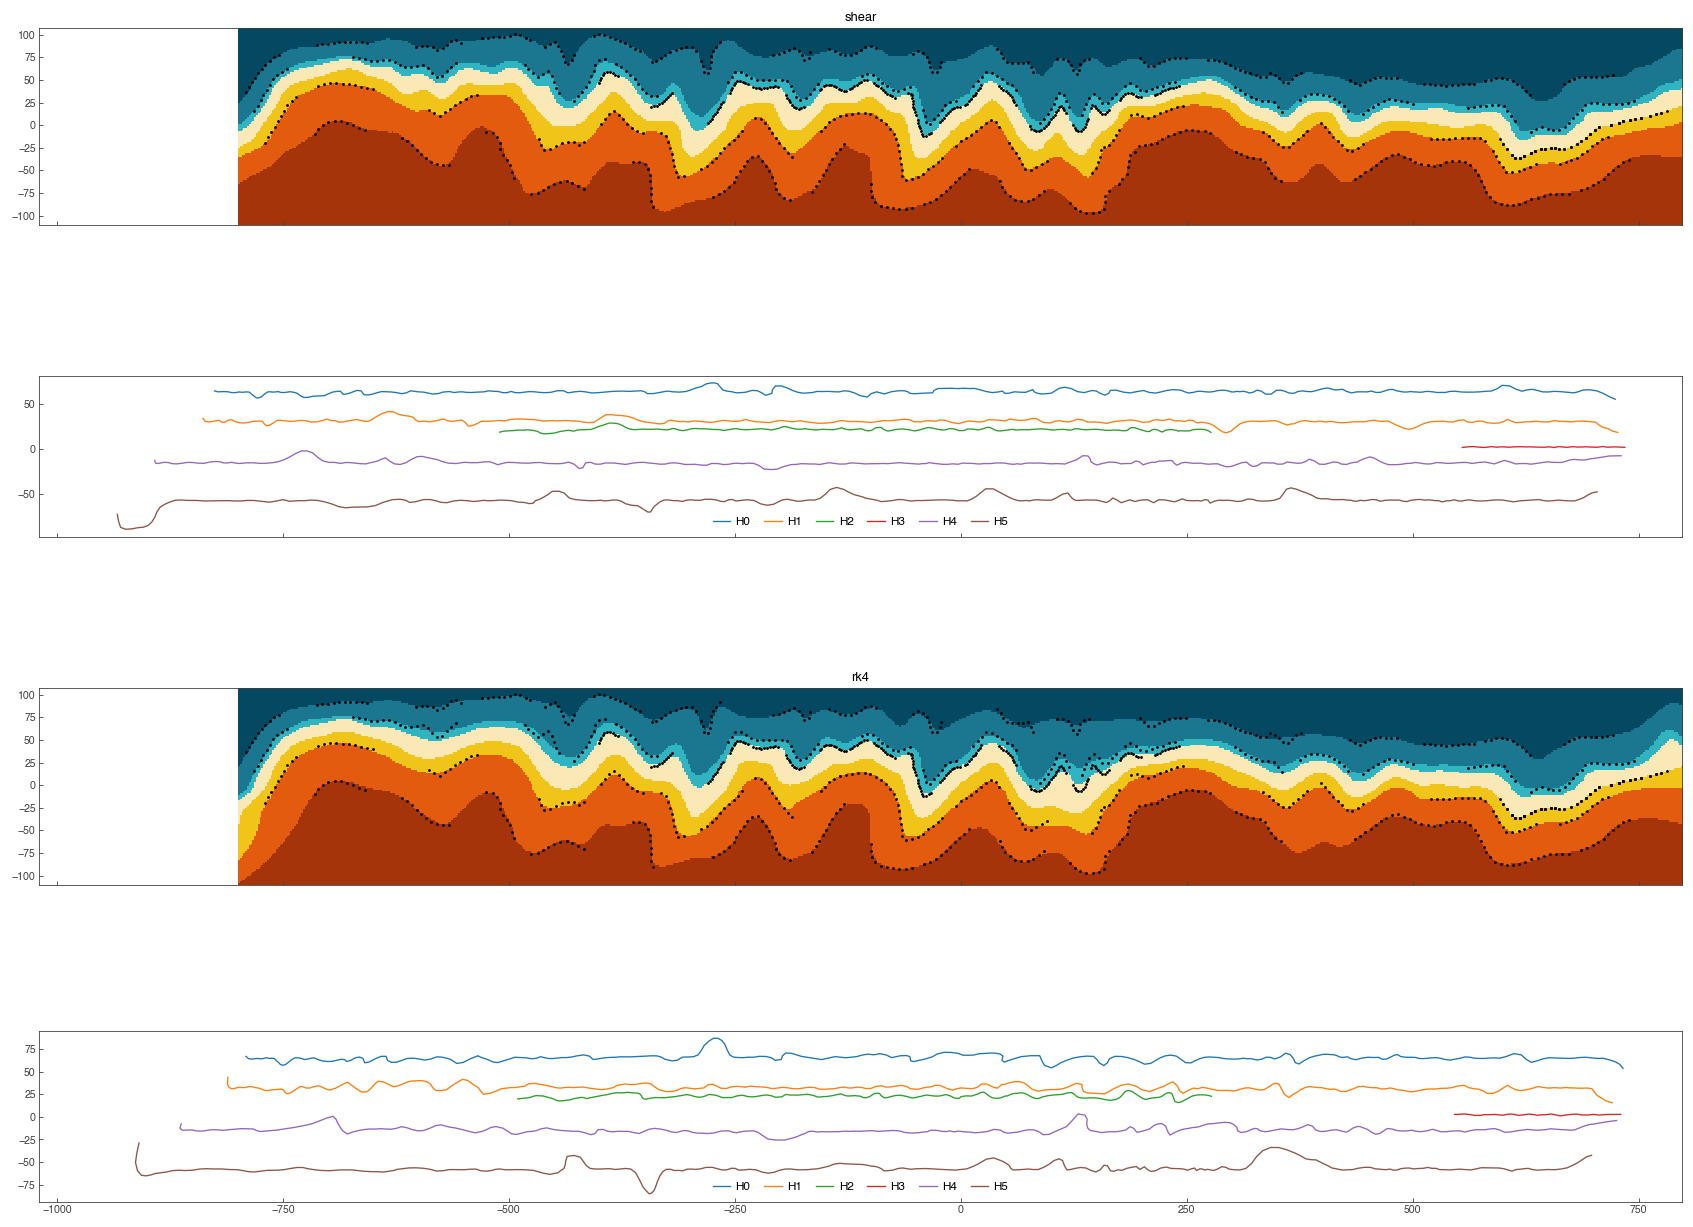

In [18]:
fig, axs = plt.subplots(2 * len(runs), 1, figsize=(14, 5.5 * len(runs)), constrained_layout=True, sharex=True)
for k, (integrator, R) in enumerate(runs.items()):
    ax_l, ax_r = axs[2 * k], axs[2 * k + 1]
    ax_l.imshow(R["lithology"].T, origin="lower", extent=(*xlim, *zlim), cmap=curlew.ccmap, interpolation="nearest")
    for h in horizons:
        ax_l.scatter(h[:, 0], h[:, 1], color="k", s=0.5)
    for n, r in zip(horizon_names, R["restored_full"]):
        ax_r.plot(r[:, 0], r[:, 1], lw=0.8, label=n)
    ax_l.set_title(integrator)
    ax_r.legend(ncol=6, fontsize=7, loc="lower center")
for ax in axs:
    ax.set_aspect("equal")
plt.show()

## Save

In [19]:
for integrator, R in runs.items():
    out_dir = bfi.results_dir(integrator)
    strain, det = R["strain"], R["det"]
    np.savez_compressed(
        out_dir / "fit.npz",
        x=np.asarray(domaxes[0], dtype=float), z=np.asarray(domaxes[1], dtype=float), anchor=anchor_xy,
        lithology=R["lithology"].astype(np.int8), det=det.astype(np.float32),
        **{f"restored_{i}": r for i, r in enumerate(R["restored_full"])},
        strain_points=strain["points"], strain_stretches=strain["stretches"], strain_angles=strain["angles"],
        strain_Rs=strain["Rs"], strain_det=strain["det"], strain_radius=strain_radius,
        path_seeds=path_seeds, factor_names=np.asarray(R["factor_names"]),
        **{f"pathlines_{i}": p.astype(np.float32) for i, p in enumerate(R["pathlines"])},
        paleo=paleo.astype(np.float32), present=R["present"].astype(np.float32),
        z_lines=z_lines, x_lines=x_lines, s_z=s_z, n_along=N_ALONG,
        **{f"modes_{i}_{k}": a for i, m in enumerate(R["modes"]) for k, a in zip(("direction", "wavelength", "amplitude"), m)},
        n_factors=len(R["modes"]), lsr=np.asarray(LSR, dtype=float),
    )
    torch.save(R["event"].field.state_dict(), out_dir / "restore_field.pt")
    summary = {
        "integrator": integrator, "n_steps": bfi.INTEGRATORS[integrator], "fit_seconds": R["fit_seconds"],
        "restored_depth_mean": dict(zip(horizon_names, R["depth_mean"])),
        "restored_depth_sd": dict(zip(horizon_names, R["depth_sd"])),
        "in_order": R["in_order"], "max_abs_det_minus_1": float(np.abs(det - 1).max()),
        "shortening": {k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in R["shortening"].items()},
        "strain_Rs_median": float(np.median(strain["Rs"])),
    }
    (out_dir / "summary.json").write_text(json.dumps(summary, indent=1))
    (out_dir / "fit_settings.json").write_text(json.dumps(dict(
        integrator=integrator, n_steps=bfi.INTEGRATORS[integrator], lsr=[float(v) for v in LSR], n_features=N_FEATURES,
        n_directions=N_DIRECTIONS, modes_per_octave=MODES_PER_OCTAVE, band_info=BAND_INFO, fourier_seed=FOURIER_SEED, epochs=EPOCHS, weights=WEIGHTS,
        iq_samples=IQ_SAMPLES, energy_normalised=True, init_std=INIT_STD,
        lr_adam=LR_ADAM, lr_sgd=LR_SGD, amp_momentum=AMP_MOMENTUM, spectral_warmup=SPECTRAL_WARMUP,
    ), indent=2))
    for f in sorted(out_dir.iterdir()):
        print(f"wrote {f}  ({f.stat().st_size / 1e6:.2f} MB)")

wrote results/shear/fit.npz  (2.03 MB)
wrote results/shear/fit_settings.json  (0.00 MB)
wrote results/shear/restore_field.pt  (0.03 MB)
wrote results/shear/summary.json  (0.00 MB)
wrote results/rk4/fit.npz  (2.05 MB)
wrote results/rk4/fit_settings.json  (0.00 MB)
wrote results/rk4/restore_field.pt  (0.03 MB)
wrote results/rk4/summary.json  (0.00 MB)
